In [2]:
import pandas as pd
import numpy as np
from pathlib import Path

import matplotlib.pyplot as plt

## Loading data from that was saved in previous notebook (lr_model_features.ipynb)

In [3]:
import pickle

data_dir = Path("../procdata_para_thresh/")

dev_demo = pd.read_pickle(data_dir / "dev_demo.pkl")
df_test = pd.read_pickle(data_dir / "df_test.pkl")

with open(data_dir / "folds.pkl", "rb") as f:
    folds = pickle.load(f)



print("Development dataset:", dev_demo.shape)
print("Final test dataset:", df_test.shape)
print("Number of CV folds:", len(folds))


Development dataset: (1815, 72)
Final test dataset: (461, 70)
Number of CV folds: 3


In [4]:
for i, (fit_idx, val_idx) in enumerate(folds, start=1):

    assert set(fit_idx).issubset(dev_demo.index)
    assert set(val_idx).issubset(dev_demo.index)
    assert set(fit_idx).isdisjoint(val_idx)

    print(
        f"Fold {i}: "
        f"{len(fit_idx)} training, "
        f"{len(val_idx)} validation"
    )

print("All folds look good")

Fold 1: 629 training, 351 validation
Fold 2: 980 training, 350 validation
Fold 3: 1330 training, 368 validation
All folds look good


# 20 Feature set we decided

In [5]:

numeric_features = [
    "steps",
    "calories",
    "sedentary_minutes",
    "lightly_active_minutes",
    "moderately_active_minutes",
    "very_active_minutes",
    "bpm",
    "sleep_hours",
    "resting_hr",
    "sleep_efficiency"
]

demographic_features = [
    "age",
    "gender",
    "bmi_group"
]

historical_moods = [
    "ALERT",
    "HAPPY",
    "NEUTRAL",
    "RESTED/RELAXED",
    "SAD",
    "TENSE/ANXIOUS",
    "TIRED"
]

next_cols = [
    f"{mood}_next"
    for mood in historical_moods
]

all_features = (
    numeric_features
    + demographic_features
    + historical_moods
)

print("Total features:", len(all_features))
print("Targets:", len(next_cols))


Total features: 20
Targets: 7


## Comparing Logistic regression, XGB, KNN , Random forrest

In [6]:


from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)







dev = dev_demo.copy()


dev["sleep_hours"] = (
    dev["sleep_duration"] / 3_600_000
)


for col in demographic_features:
    dev[col] = (
        dev[col]
        .astype("string")
        .fillna("Missing")
        .astype(str)
    )


# Preprocessors

preprocessor = ColumnTransformer([
    (
        "num",
        make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler()
        ),
        numeric_features
    ),
    (
        "demo",
        OneHotEncoder(handle_unknown="ignore"),
        demographic_features
    ),
    (
        "moods",
        make_pipeline(
            SimpleImputer(
                strategy="constant",
                fill_value=-1
            ),
            OneHotEncoder(handle_unknown="ignore")
        ),
        historical_moods
    )
])

# Cross validation

results_models = []

for fold_num, (fit_idx, val_idx) in enumerate(folds, start=1):

    fold_fit = dev.loc[fit_idx]
    fold_val = dev.loc[val_idx]

    # Fit preprocessing 
    X_fit = preprocessor.fit_transform(
        fold_fit[all_features]
    )

    X_val = preprocessor.transform(
        fold_val[all_features]
    )

 
    if hasattr(X_fit, "toarray"):
        X_fit = X_fit.toarray()
        X_val = X_val.toarray()

    for target in next_cols:

        y_fit = fold_fit[target].astype(int)
        y_val = fold_val[target].astype(int)

        models = {
            "Logistic": LogisticRegression(
                max_iter=2000
            ),

            "KNN": KNeighborsClassifier(
                n_neighbors=15
            ),

            "XGBoost": XGBClassifier(
                n_estimators=200,
                max_depth=3,
                learning_rate=0.05,
                subsample=0.8,
                colsample_bytree=0.8,
                eval_metric="logloss",
                random_state=216,
                n_jobs=2
            ),

            "Random Forest": RandomForestClassifier(
                n_estimators=300,
                max_depth=6,
                min_samples_leaf=5,
                random_state=216,
                n_jobs=2
            )
        }

        for name, model in models.items():

            model.fit(X_fit, y_fit)

            probabilities = model.predict_proba(
                X_val
            )[:, 1]

            auc = (
                roc_auc_score(y_val, probabilities)
                if y_val.nunique() == 2 else np.nan
            )

            pr_auc = (
                average_precision_score(y_val, probabilities)
                if y_val.sum() > 0 else np.nan
            )

            brier = brier_score_loss(
                y_val, probabilities
            )

            results_models.append({
                "Fold": fold_num,
                "Mood": target,
                "Model": name,
                "AUC": auc,
                "PR_AUC": pr_auc,
                "Brier": brier
            })




models_df = pd.DataFrame(results_models)

print("RESULTS FOR EACH FOLD")
print(models_df.round(3).to_string(index=False))


RESULTS FOR EACH FOLD
 Fold                Mood         Model   AUC  PR_AUC  Brier
    1          ALERT_next      Logistic 0.706   0.293  0.103
    1          ALERT_next           KNN 0.733   0.324  0.098
    1          ALERT_next       XGBoost 0.666   0.302  0.106
    1          ALERT_next Random Forest 0.700   0.309  0.098
    1          HAPPY_next      Logistic 0.556   0.359  0.211
    1          HAPPY_next           KNN 0.662   0.422  0.196
    1          HAPPY_next       XGBoost 0.610   0.395  0.210
    1          HAPPY_next Random Forest 0.640   0.418  0.198
    1        NEUTRAL_next      Logistic 0.654   0.440  0.181
    1        NEUTRAL_next           KNN 0.645   0.428  0.184
    1        NEUTRAL_next       XGBoost 0.621   0.387  0.192
    1        NEUTRAL_next Random Forest 0.663   0.439  0.176
    1 RESTED/RELAXED_next      Logistic 0.684   0.601  0.218
    1 RESTED/RELAXED_next           KNN 0.667   0.512  0.219
    1 RESTED/RELAXED_next       XGBoost 0.666   0.522  0.225
  

### Mean and standard deviation accross folds for each mood and each model

In [7]:

# Calculate mean and standard deviation
# across the three chronological folds

model_summary = (
    models_df
    .groupby(["Mood", "Model"])[
        ["AUC", "PR_AUC", "Brier"]
    ]
    .agg(["mean", "std"])
)

print("MODEL COMPARISON SUMMARY")
print(model_summary.round(3).to_string())


MODEL COMPARISON SUMMARY
                                     AUC        PR_AUC         Brier       
                                    mean    std   mean    std   mean    std
Mood                Model                                                  
ALERT_next          KNN            0.761  0.025  0.350  0.060  0.093  0.005
                    Logistic       0.758  0.045  0.336  0.040  0.093  0.009
                    Random Forest  0.745  0.040  0.388  0.083  0.091  0.008
                    XGBoost        0.748  0.072  0.381  0.071  0.093  0.013
HAPPY_next          KNN            0.628  0.030  0.373  0.045  0.205  0.009
                    Logistic       0.585  0.043  0.375  0.070  0.203  0.007
                    Random Forest  0.636  0.030  0.400  0.056  0.197  0.002
                    XGBoost        0.626  0.042  0.392  0.061  0.203  0.008
NEUTRAL_next        KNN            0.706  0.059  0.502  0.065  0.182  0.014
                    Logistic       0.703  0.043  0.515  0.066  

## Plot of performance of each model accross Moods

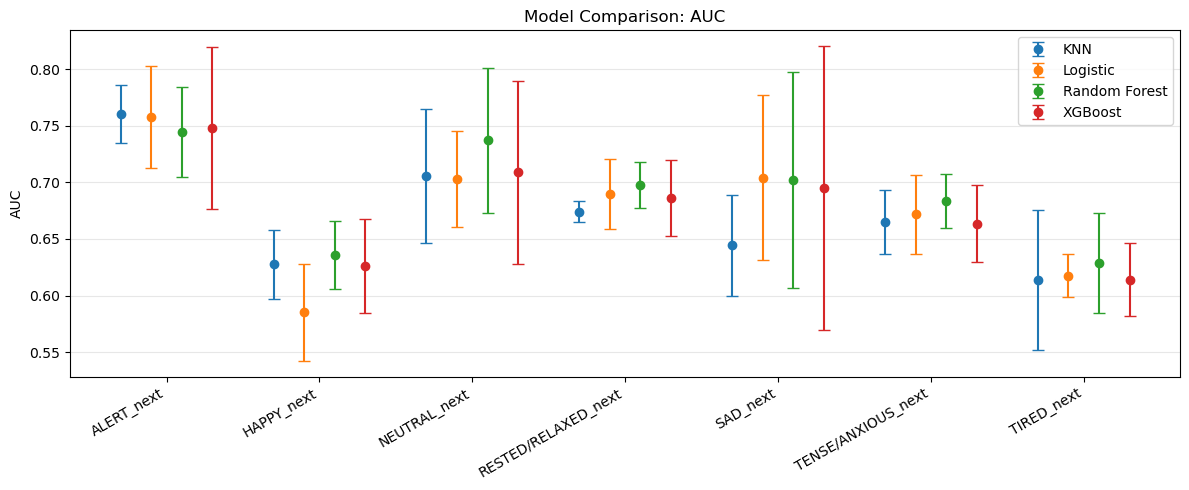

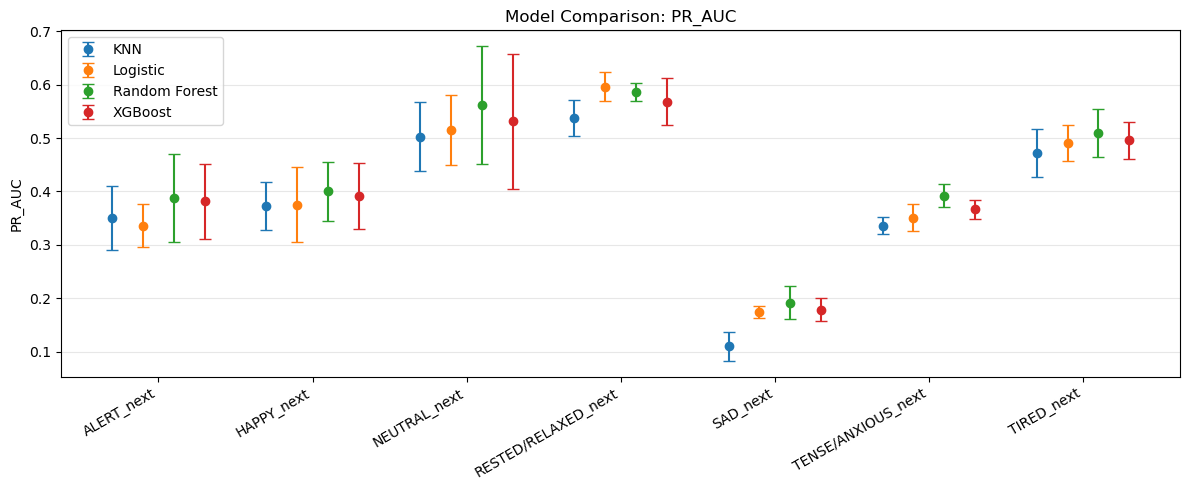

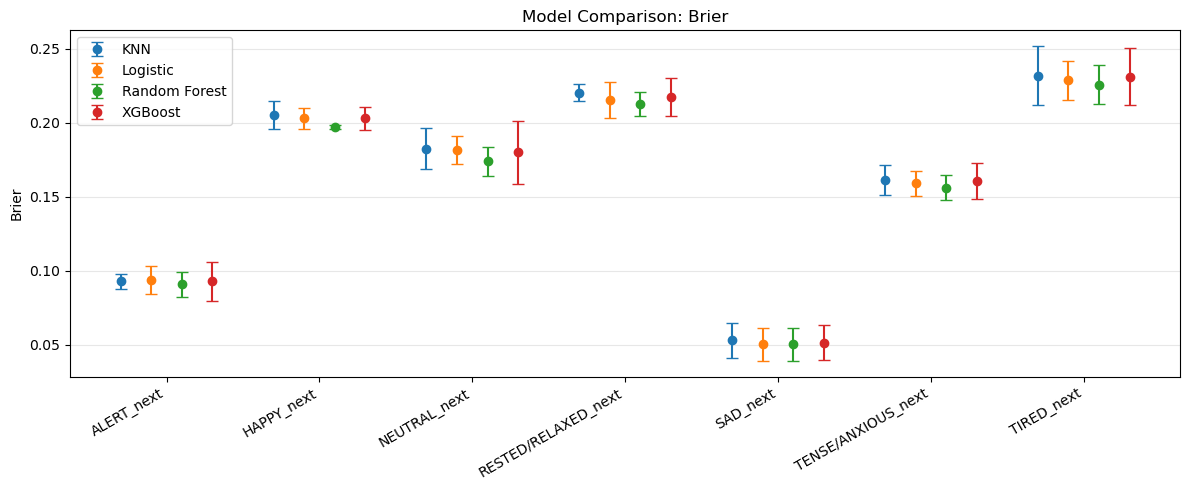

In [8]:


metrics = ["AUC", "PR_AUC", "Brier"]
models = model_summary.index.get_level_values("Model").unique()  # the model list is heree
moods = model_summary.index.get_level_values("Mood").unique()  # the 7 moodess

for metric in metrics:

    fig, ax = plt.subplots(figsize=(12, 5))

    x = np.arange(len(moods))
    offsets = np.linspace(-0.3, 0.3, len(models))

    for i, model in enumerate(models):

        means = [
            model_summary.loc[(mood, model), (metric, "mean")]
            for mood in moods
        ]

        stds = [
            model_summary.loc[(mood, model), (metric, "std")]
            for mood in moods
        ]

        ax.errorbar(
            x + offsets[i],
            means,
            yerr=stds,
            marker="o",
            capsize=4,
            linestyle="none",
            label=model
        )

    ax.set_xticks(x)
    ax.set_xticklabels(
        moods,
        rotation=30,
        ha="right"
    )

    ax.set_ylabel(metric)
    ax.set_title(f"Model Comparison: {metric}")
    ax.legend()
    ax.grid(axis="y", alpha=0.3)

    plt.tight_layout()

    plt.savefig(
    f"../figures/model_comparison/{metric}_across_algorithms.png",
    dpi=300,
    bbox_inches="tight"
    )
    plt.show()

Random forrest Performed slightly better than other Models. Might be because Random Forest can learn nonlinear relationships and interactions between predictors.

For example, someone's current mood, sleep duration, and physical activity might jointly contain predictive information even when their individual associations are weak.


Since most of the features are best for random forrest , we can choose that for tuning and next steps.

## HyperParameters Combinations for Random Forrest Tuning

In [41]:

from sklearn.model_selection import ParameterGrid
from sklearn.base import clone



param_grid = {
    "max_depth": [4, 6, 10],
    "min_samples_leaf": [3, 5, 10]
}

param_combinations = list(ParameterGrid(param_grid))

print("Configurations per mood:", len(param_combinations))



tuning_results = []

for fold_num, (fit_idx, val_idx) in enumerate(folds, start=1):

    fold_fit = dev.loc[fit_idx]
    fold_val = dev.loc[val_idx]

    
    prep = clone(preprocessor)

    X_fit = prep.fit_transform(fold_fit[all_features])
    X_val = prep.transform(fold_val[all_features])

    if hasattr(X_fit, "toarray"):
        X_fit = X_fit.toarray()
        X_val = X_val.toarray()

    for target in next_cols:

        y_fit = fold_fit[target].astype(int)
        y_val = fold_val[target].astype(int)

        for params in param_combinations:

            model = RandomForestClassifier(
                n_estimators=300,
                max_depth=params["max_depth"],
                min_samples_leaf=params["min_samples_leaf"],
                random_state=216,
                n_jobs=2
            )

            model.fit(X_fit, y_fit)

            probabilities = model.predict_proba(X_val)[:, 1]

            auc = (
                roc_auc_score(y_val, probabilities)
                if y_val.nunique() == 2 else np.nan
            )

            pr_auc = (
                average_precision_score(y_val, probabilities)
                if y_val.sum() > 0 else np.nan
            )

            brier = brier_score_loss(y_val, probabilities)

            tuning_results.append({
                "Fold": fold_num,
                "Mood": target,
                "max_depth": params["max_depth"],
                "min_samples_leaf": params["min_samples_leaf"],
                "AUC": auc,
                "PR_AUC": pr_auc,
                "Brier": brier
            })



tuning_df = pd.DataFrame(tuning_results)

# Aveage over folds

tuning_summary = (
    tuning_df
    .groupby([
        "Mood",
        "max_depth",
        "min_samples_leaf"
    ])[["AUC", "PR_AUC", "Brier"]]
    .mean()
    .reset_index()
)

# best hyper parameter set for each

best_rf = (
    tuning_summary
    .sort_values(
        ["Mood", "PR_AUC", "Brier"],
        ascending=[True, False, True]
    )
    .drop_duplicates(subset="Mood")
    .sort_values("Mood")
    .reset_index(drop=True)
)

print("BEST RANDOM FOREST HYPERPARAMETERS")
print(best_rf.round(3).to_string(index=False))


Configurations per mood: 9
BEST RANDOM FOREST HYPERPARAMETERS
               Mood  max_depth  min_samples_leaf   AUC  PR_AUC  Brier
         ALERT_next         10                 5 0.756   0.405  0.090
         HAPPY_next         10                10 0.646   0.411  0.196
       NEUTRAL_next         10                10 0.739   0.573  0.172
RESTED/RELAXED_next          6                10 0.704   0.590  0.212
           SAD_next         10                 5 0.706   0.195  0.050
 TENSE/ANXIOUS_next         10                10 0.690   0.408  0.155
         TIRED_next          4                 5 0.624   0.515  0.227


### Different Depths in Random Forrest

In [42]:

# For each mood and tree depth, find the best PR-AUC


depth_summary = (
    tuning_summary
    .groupby(["Mood", "max_depth"])["PR_AUC"]
    .max()
    .unstack("max_depth")
)

print("BEST PR-AUC AT EACH TREE DEPTH")
print(depth_summary.round(3).to_string())


BEST PR-AUC AT EACH TREE DEPTH
max_depth               4      6      10
Mood                                    
ALERT_next           0.399  0.391  0.405
HAPPY_next           0.393  0.402  0.411
NEUTRAL_next         0.563  0.566  0.573
RESTED/RELAXED_next  0.589  0.590  0.582
SAD_next             0.185  0.191  0.195
TENSE/ANXIOUS_next   0.388  0.408  0.408
TIRED_next           0.515  0.509  0.506


### Different min-sample leaf in Random Forrest

In [43]:
# For each mood and min-sample leaf, find the best PR-AUC


min_leaf_summary = (
    tuning_summary
    .groupby(["Mood", "min_samples_leaf"])["PR_AUC"]
    .max()
    .unstack("min_samples_leaf")
)

print("BEST PR-AUC AT EACH min_samples_leaf")
print(min_leaf_summary.round(3).to_string())

BEST PR-AUC AT EACH min_samples_leaf
min_samples_leaf        3      5      10
Mood                                    
ALERT_next           0.399  0.405  0.393
HAPPY_next           0.400  0.405  0.411
NEUTRAL_next         0.566  0.563  0.573
RESTED/RELAXED_next  0.587  0.589  0.590
SAD_next             0.188  0.195  0.182
TENSE/ANXIOUS_next   0.404  0.392  0.408
TIRED_next           0.509  0.515  0.507


Results for depth and min-leaf seem to be saturated . So we move on with the best parameters we obtained in best_rf_params. And this best_rf_params will be used in further analysis.

## Probability Prediction on validation set using best hyperparameter combinations of random forrest

In [44]:


best_rf_params = {
    row["Mood"]: {
        "max_depth": int(row["max_depth"]),
        "min_samples_leaf": int(row["min_samples_leaf"])
    }
    for _, row in best_rf.iterrows()
}


tuned_validation_predictions = []

for fold_num, (fit_idx, val_idx) in enumerate(folds, start=1):

    fold_fit = dev.loc[fit_idx]
    fold_val = dev.loc[val_idx]

   
    prep = clone(preprocessor)

    X_fit = prep.fit_transform(
        fold_fit[all_features]
    )

    X_val = prep.transform(
        fold_val[all_features]
    )

    if hasattr(X_fit, "toarray"):
        X_fit = X_fit.toarray()
        X_val = X_val.toarray()

    for target in next_cols:

        y_fit = fold_fit[target].astype(int)
        y_val = fold_val[target].astype(int)

        # Retrieve tuned hyperparameters
        params = best_rf_params[target]

        model = RandomForestClassifier(
            n_estimators=300,
            max_depth=params["max_depth"],
            min_samples_leaf=params["min_samples_leaf"],
            random_state=216,
            n_jobs=2
        )

        model.fit(X_fit, y_fit)

        probabilities = model.predict_proba(
            X_val
        )[:, 1]

        tuned_validation_predictions.append(
            pd.DataFrame({
                "Fold": fold_num,
                "Mood": target,
                "Actual": y_val.to_numpy(),
                "Probability": probabilities
            })
        )

# Combine all 
tuned_validation_df = pd.concat(
    tuned_validation_predictions,
    ignore_index=True
)


print(tuned_validation_df.shape)

print(tuned_validation_df.head())

(7483, 4)
   Fold        Mood  Actual  Probability
0     1  ALERT_next       0     0.042525
1     1  ALERT_next       0     0.067245
2     1  ALERT_next       0     0.074136
3     1  ALERT_next       0     0.071964
4     1  ALERT_next       0     0.096637


### Selecting threshold with highest F1 score for each mood

In [45]:

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)



# Thresholds range
thresholds = np.arange(0.05, 0.51, 0.01)

threshold_results = []

for mood in next_cols:

    # Validation predictions from tuned Random Forest
    data = tuned_validation_df[
        tuned_validation_df["Mood"] == mood
    ]

    y_true = data["Actual"].to_numpy()
    probabilities = data["Probability"].to_numpy()

    for threshold in thresholds:

        y_pred = (
            probabilities >= threshold
        ).astype(int)

        threshold_results.append({
            "Mood": mood,
            "Threshold": round(threshold, 2),

            "Precision": precision_score(
                y_true, y_pred, zero_division=0
            ),

            "Recall": recall_score(
                y_true, y_pred, zero_division=0
            ),

            "F1": f1_score(
                y_true, y_pred, zero_division=0
            ),

            "Predicted_positives": y_pred.sum()
        })


tuned_threshold_df = pd.DataFrame(threshold_results)

# Select threshold with highest F1 for each mood
best_tuned_thresholds = (
    tuned_threshold_df
    .sort_values(
        ["Mood", "F1", "Threshold"],
        ascending=[True, False, False]
    )
    .drop_duplicates(subset="Mood")
    .sort_values("Mood")
    .reset_index(drop=True)
)

print("BEST THRESHOLDS — TUNED RANDOM FOREST")
print(best_tuned_thresholds.round(3).to_string(index=False))


BEST THRESHOLDS — TUNED RANDOM FOREST
               Mood  Threshold  Precision  Recall    F1  Predicted_positives
         ALERT_next       0.30      0.439   0.403 0.420                  114
         HAPPY_next       0.27      0.362   0.754 0.489                  643
       NEUTRAL_next       0.33      0.590   0.557 0.573                  290
RESTED/RELAXED_next       0.36      0.495   0.770 0.602                  651
           SAD_next       0.15      0.281   0.305 0.293                   64
 TENSE/ANXIOUS_next       0.31      0.424   0.428 0.426                  231
         TIRED_next       0.36      0.403   0.915 0.559                  906


## Plot of recall, precision , F1 with threshold for each mood

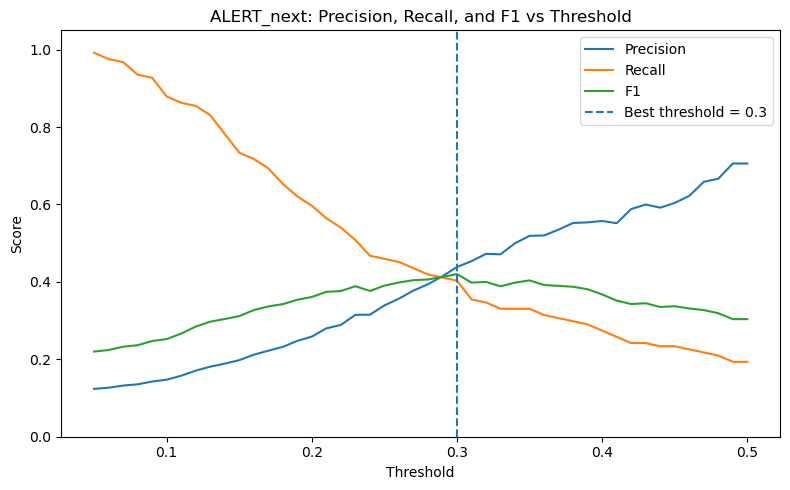

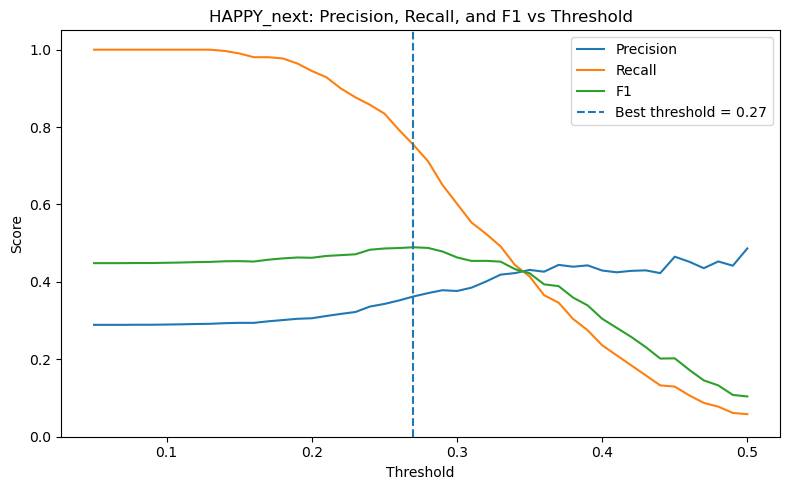

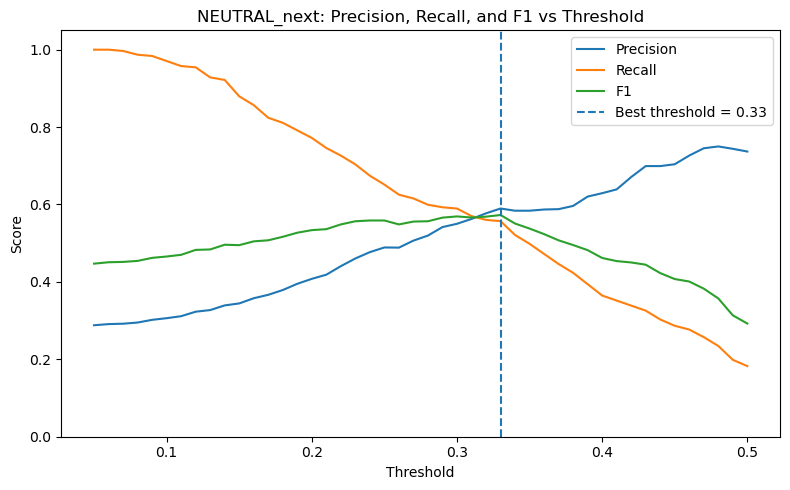

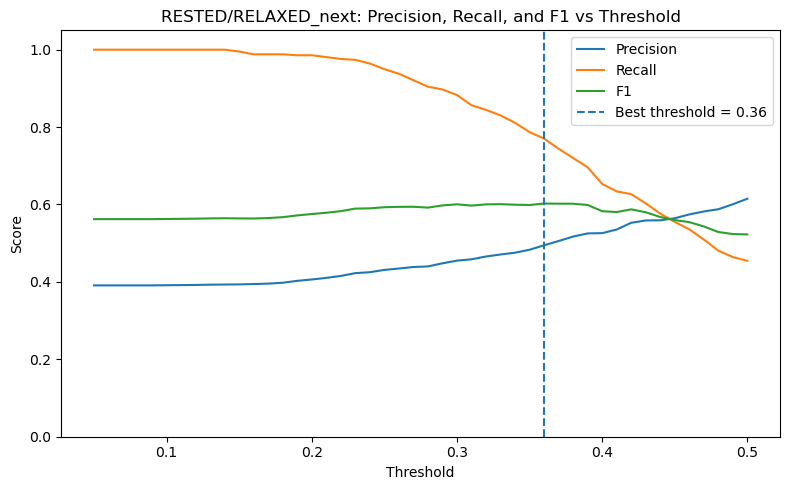

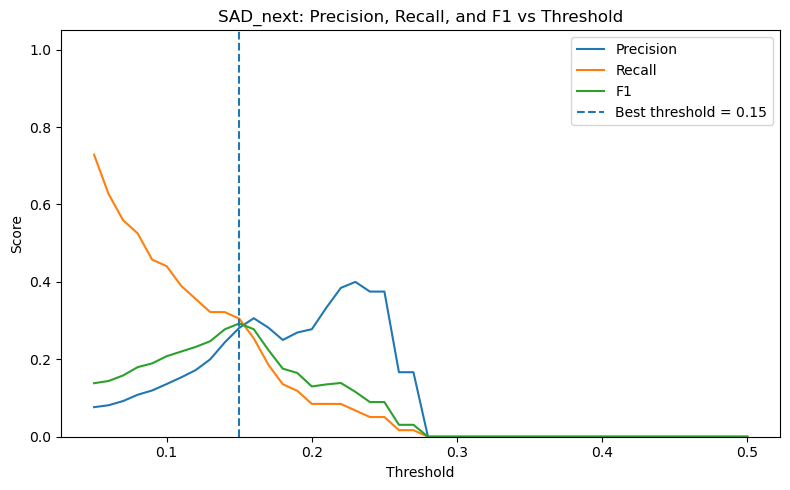

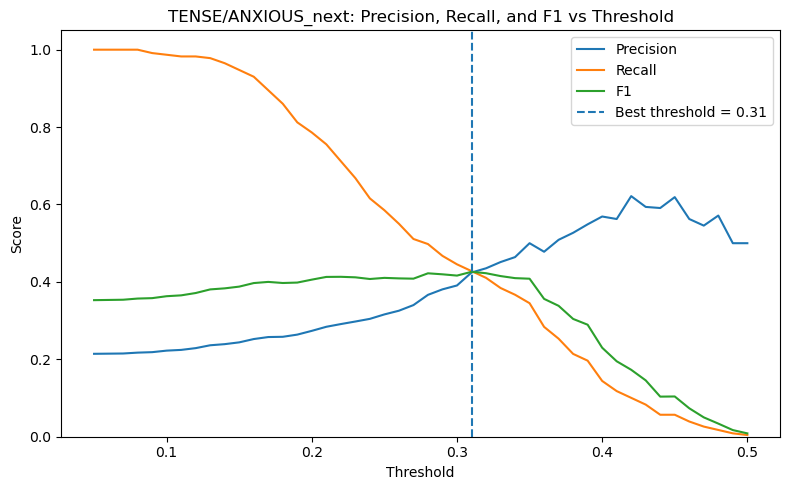

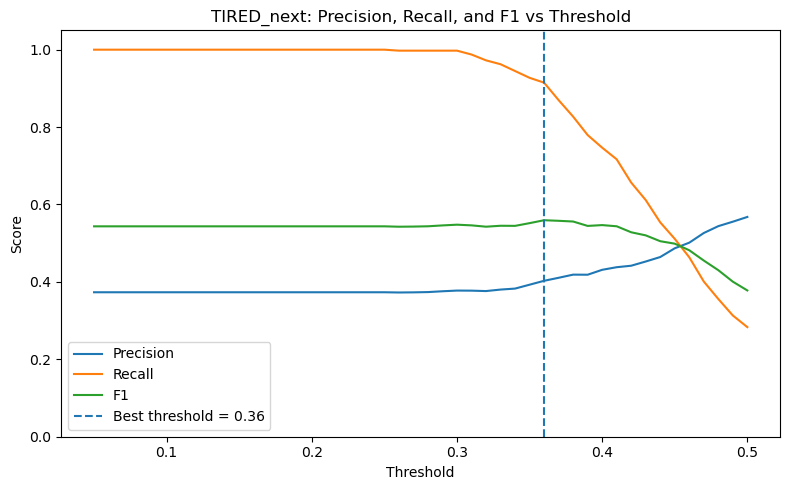

In [48]:



for mood in tuned_threshold_df["Mood"].unique():
    
    df_plot = (
        tuned_threshold_df[tuned_threshold_df["Mood"] == mood]
        .sort_values("Threshold")
    )
    
    best_row = best_tuned_thresholds[
        best_tuned_thresholds["Mood"] == mood
    ].iloc[0]
    
    best_threshold = best_row["Threshold"]
    best_f1 = best_row["F1"]

    plt.figure(figsize=(8, 5))
    
    plt.plot(df_plot["Threshold"], df_plot["Precision"], label="Precision")
    plt.plot(df_plot["Threshold"], df_plot["Recall"], label="Recall")
    plt.plot(df_plot["Threshold"], df_plot["F1"], label="F1")
    
    plt.axvline(
        best_threshold,
        linestyle="--",
        label=f"Best threshold = {best_threshold}"
    )
    
    plt.xlabel("Threshold")
    plt.ylabel("Score")
    plt.title(f"{mood}: Precision, Recall, and F1 vs Threshold")
    plt.ylim(0, 1.05)
    plt.legend()
    plt.tight_layout()
    
    safe_mood = mood.replace("/", "_")

    plt.savefig(
    f"../figures/f1_recall_precision/{safe_mood}_precision_recall_F1.png",
    dpi=300,
    bbox_inches="tight"
    )

   
    

    
    plt.show()

## Saving the best_random forrest hyperparameters and best tuned thresholds

In [47]:


output_dir = Path("../procdata_para_thresh/")
output_dir.mkdir(exist_ok=True)

best_rf.to_pickle(output_dir / "best_rf.pkl")

best_tuned_thresholds.to_pickle(
    output_dir / "best_tuned_thresholds.pkl"
)

